# How to use viewmastR

viewmastR predicts the cell types of a query dataset from a labelled reference. This
tutorial installs the package, selects shared variable genes, trains a model, and checks
its predictions. It follows the R article
[How to use viewmastR](https://furlan-lab.github.io/viewmastR/articles/HowTo.html).

| Role | Dataset |
|---|---|
| Reference | BoneMarrowMap healthy bone marrow atlas (Zeng et al. 2025), 24 broad cell types, balanced to 3,000 cells per type with `augment_data()` (tutorial 04) |
| Query | T-cell-depleted bone marrow, multiome RNA, 8,627 cells with the authors' labels and UMAP (Persad et al. 2023; the file the [Mellon](https://github.com/settylab/Mellon) tutorial uses) |

## Install

```bash
uv pip install "git+https://github.com/jacob-greene/py-viewmastR"
```

A Rust toolchain (1.86 or newer) builds the burn backend during the install.

## Load the data

Copy `data_paths.example.json` to `data_paths.json` and set `cache_dir`. Both datasets
download on first use (reference 3.7 GB, query 2.5 GB). The query is used as published: raw
counts, the authors' labels and their UMAP. Nothing is re-normalised or re-embedded.

`bonemarrowmap_augmented()` builds the reference once and caches it (about 12 GB of memory,
a few minutes). Of each type it holds out 20 % of the real cells (at most 1,000). It then
balances the other cells to 3,000 per type: large types are down-sampled, and rare types
get simulated cells. The held-out cells are real and never simulated, so they give an
honest accuracy below.

In [1]:
import matplotlib.pyplot as plt
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
label = "CellType_Broad"
ref, held = td.bonemarrowmap_augmented(label, norm_number=3000)
query = td.bm_tcelldep()
print("reference", ref.shape, "of which simulated", int(ref.obs["simulated"].sum()))
print("held out", held.shape, "query", query.shape)

reference (72000, 34009) of which simulated 6567
held out (21057, 34009) query (8627, 17226)


## The query's own labels

The authors' labels use different names from the reference, but they show which
populations to expect. The UMAP is the one stored in the file; viewmastR does not use it.
`vm.palette` gives every cell type the same colour in every figure.

celltype
Mono          4665
NaiveB         976
MonoPre        645
EryPre2        326
EryPre1        315
cDC            296
preB           217
MyeloidPre     186
Ery            157
proB           155
pDC            131
MylEry         122
HMP            121
MEP             99
HSC             95
preproB         59
CLP             38
Mega            24


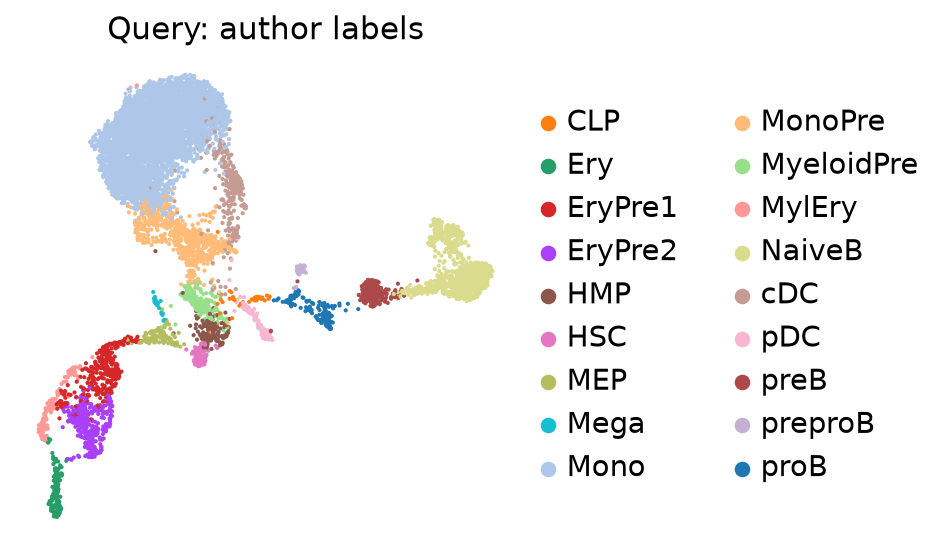

In [2]:
vm.palette.set_colors(query, "celltype")
print(query.obs["celltype"].value_counts().to_string())
sc.pl.umap(query, color="celltype", title="Query: author labels")

## Find shared variable genes

viewmastR works best on genes that vary in both datasets. For each dataset, compute the
per-gene dispersion, keep the 10,000 most dispersed genes in a mean-expression window, and
intersect the two lists. Selected genes are red; the line is the fitted mean-dispersion trend.

3784 shared variable genes


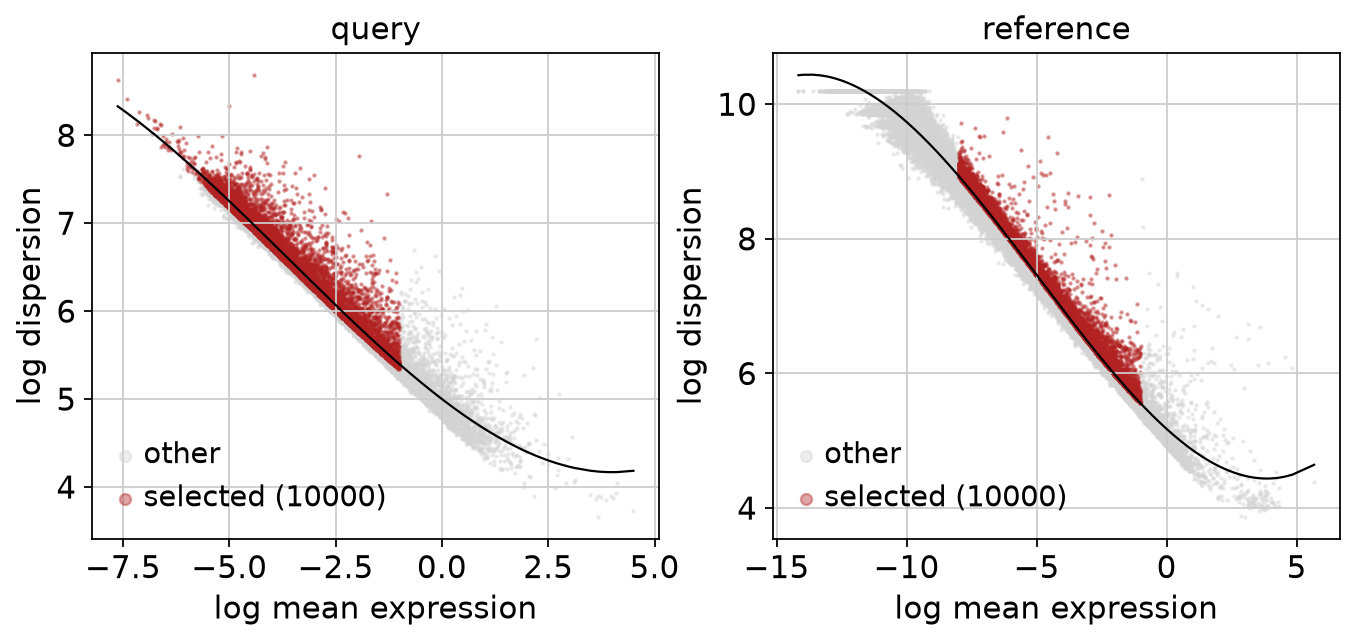

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, a) in zip(axes, [("query", query), ("reference", ref)]):
    vm.calculate_feature_dispersion(a)
    vm.select_features(a, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
    vm.plot_feature_dispersion(a, ax=ax).set_title(name)
vgr = set(vm.get_selected_features(ref))
vg = [g for g in vm.get_selected_features(query) if g in vgr]
print(f"{len(vg)} shared variable genes")

## The reference cell types

These are the labels viewmastR learns. The plot shows the real reference cells on the
atlas's stored UMAP; simulated cells have no UMAP position.

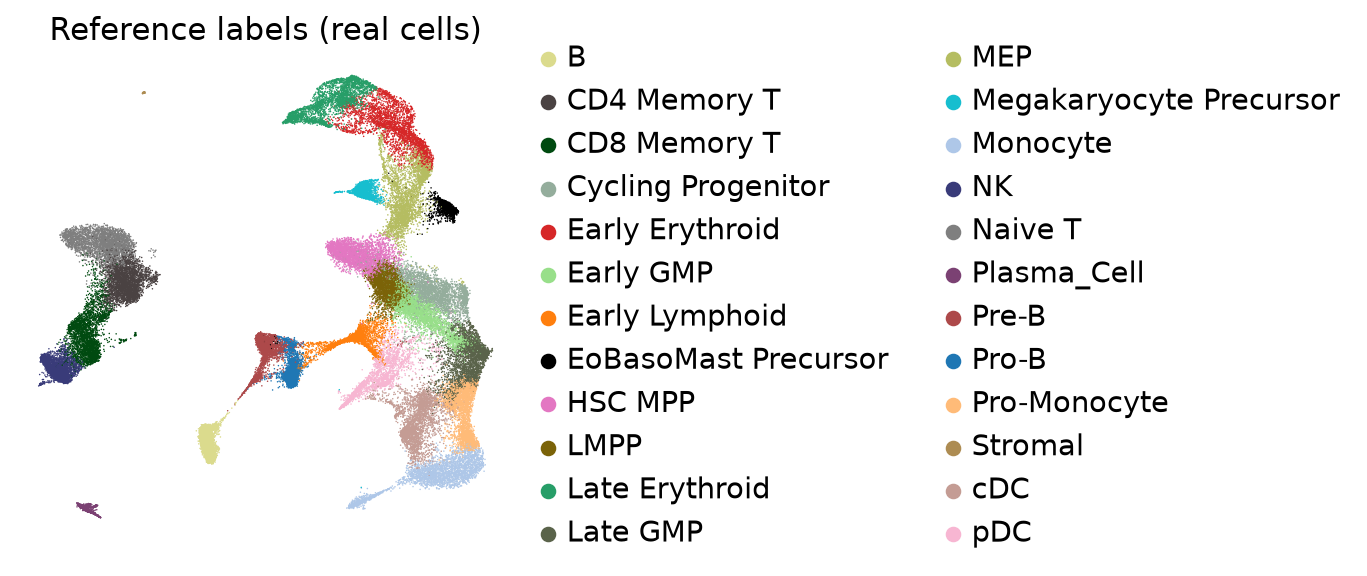

In [4]:
real = ref[~ref.obs["simulated"].to_numpy()].copy()
vm.palette.set_colors(real, label)
sc.pl.umap(real, color=label, title="Reference labels (real cells)")

## Run viewmastR

`viewmastR()` trains on the reference and writes the prediction to
`query.obs["viewmastR_pred"]`.

viewmastR: 3784 features, 24 classes, 57600 train / 14400 test cells


[epoch 1 | train accuracy 80.094% | validation accuracy 84.944%]


[epoch 2 | train accuracy 87.472% | validation accuracy 85.701%]


[epoch 3 | train accuracy 88.674% | validation accuracy 86.111%]


[epoch 4 | train accuracy 89.686% | validation accuracy 86.118%]


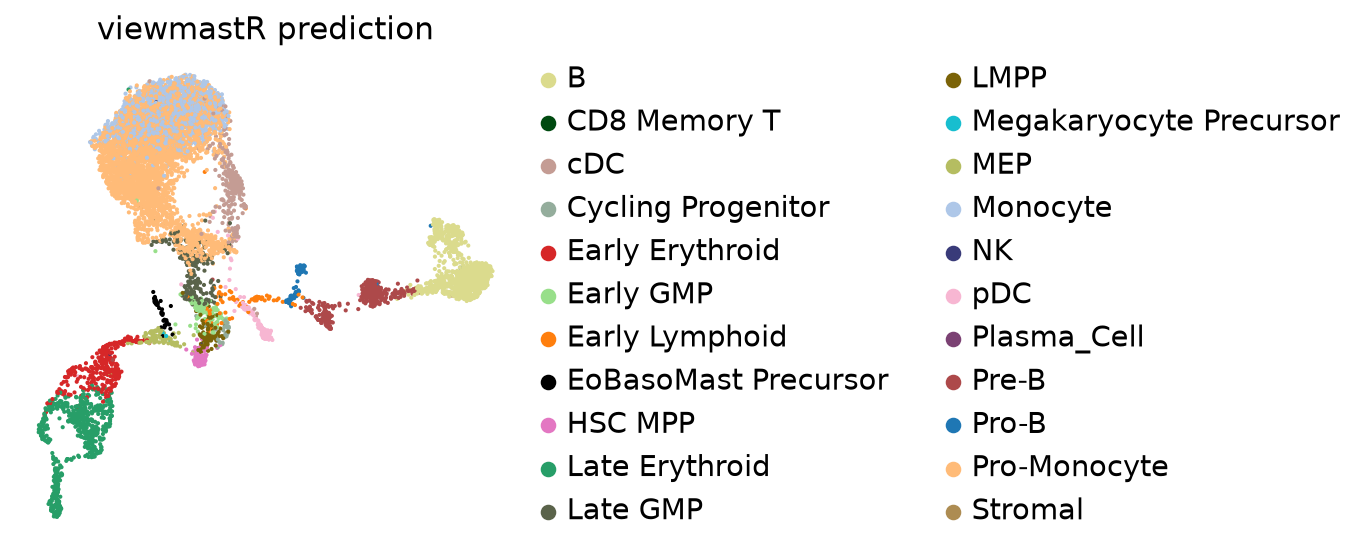

In [5]:
vm.viewmastR(query, ref, label, selected_features=vg, max_epochs=4)
vm.palette.set_colors(query, "viewmastR_pred")
sc.pl.umap(query, color="viewmastR_pred", title="viewmastR prediction")

## Compare with the author labels

Columns are the author labels; rows are the predictions; colour is the percent of each
column. The two vocabularies differ, so read this as a mapping, not an accuracy: for
example, author `HSC` maps to `HSC MPP` and author `NaiveB` to `B`. Most author `Mono`
cells get `Pro-Monocyte`, not `Monocyte`: the atlas splits the monocyte lineage more
finely than the query authors did. No author `Mega` cell gets `Megakaryocyte Precursor`.

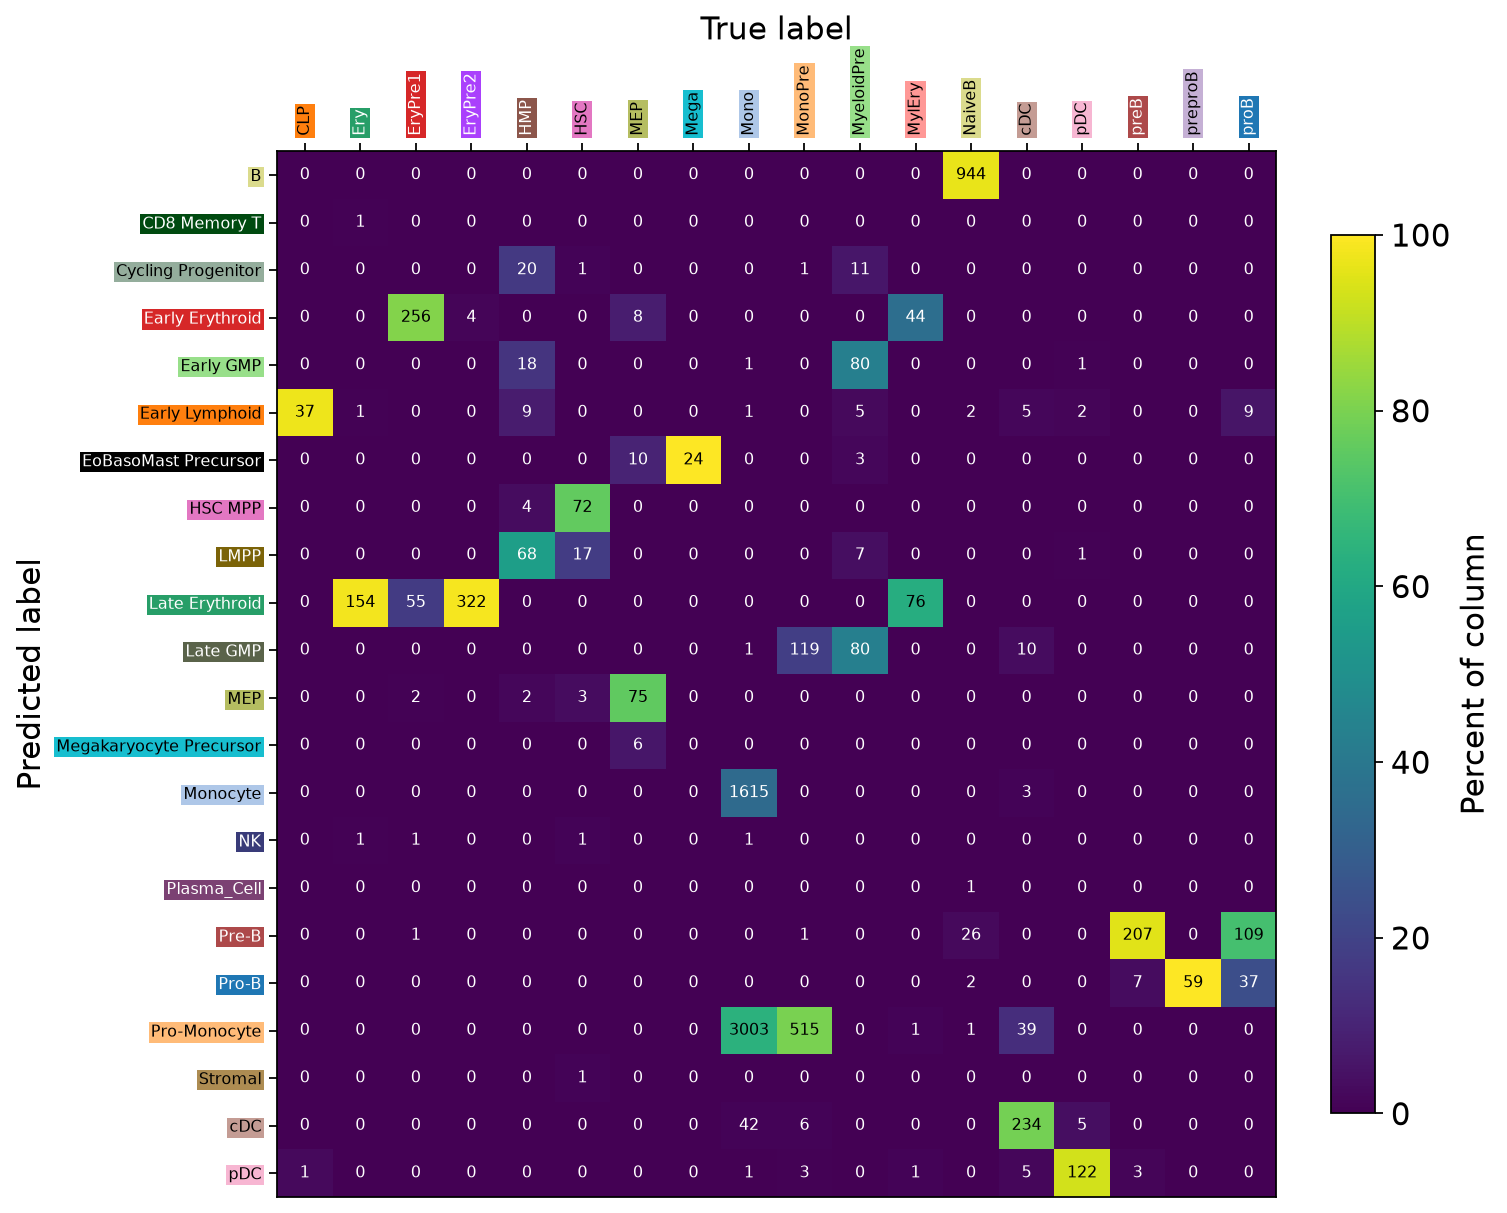

In [6]:
vm.confusion_matrix(query.obs["viewmastR_pred"], query.obs["celltype"],
                    cols=vm.palette.colors([*query.obs["viewmastR_pred"], *query.obs["celltype"]]))
plt.show()

## Training history

`return_type="list"` also returns the per-epoch accuracy and loss. If training loss keeps
falling while validation loss rises, the model over-fits. The validation cells here come
from the augmented reference, so some are simulated.

viewmastR: 3784 features, 24 classes, 57600 train / 14400 test cells


[epoch 1 | train accuracy 80.036% | validation accuracy 85.493%]


[epoch 2 | train accuracy 87.234% | validation accuracy 86.236%]


[epoch 3 | train accuracy 88.528% | validation accuracy 86.507%]


[epoch 4 | train accuracy 89.464% | validation accuracy 86.597%]


[epoch 5 | train accuracy 90.241% | validation accuracy 86.681%]


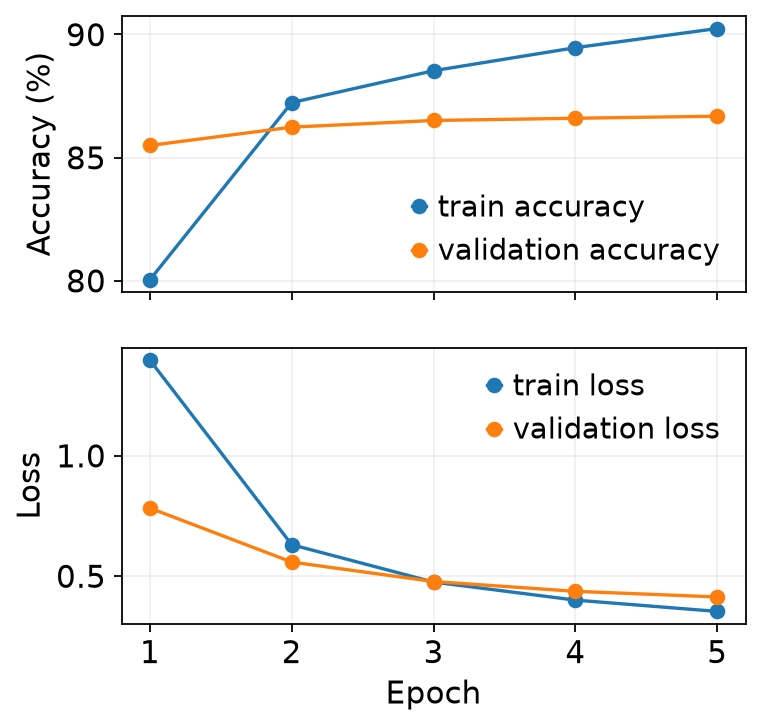

In [7]:
res = vm.viewmastR(query, ref, label, selected_features=vg, return_type="list")
vm.plot_training_data(res)
plt.show()

## Accuracy on held-out real cells

`viewmastR_infer()` labels the held-out real reference cells with the saved model.
Recall = share of a type's held-out cells that get the right label.

In [8]:
vm.viewmastR_infer(held, res.model_dir, query_celldata_col="pred")
hit = held.obs["pred"].astype(str) == held.obs[label].astype(str)
print(f"accuracy {hit.mean():.3f}, mean recall over types {hit.groupby(held.obs[label], observed=True).mean().mean():.3f}")
print(hit.groupby(held.obs[label], observed=True).mean().round(3).sort_values().to_string())

accuracy 0.848, mean recall over types 0.858
CellType_Broad
LMPP                       0.646
Early GMP                  0.705
Late GMP                   0.739
Cycling Progenitor         0.750
Pro-Monocyte               0.777
MEP                        0.810
CD4 Memory T               0.835
cDC                        0.861
EoBasoMast Precursor       0.863
CD8 Memory T               0.865
pDC                        0.867
HSC MPP                    0.869
Pre-B                      0.872
Megakaryocyte Precursor    0.879
Naive T                    0.879
Early Lymphoid             0.886
Early Erythroid            0.890
Late Erythroid             0.901
Monocyte                   0.903
Pro-B                      0.910
NK                         0.922
Stromal                    0.976
B                          0.992
Plasma_Cell                0.996


## Probabilities

`return_probs=True` adds one `prob_<label>` column per class: the softmax of the model's
log-odds. Four of the 24 classes are shown.

viewmastR: 3784 features, 24 classes, 57600 train / 14400 test cells


[epoch 1 | train accuracy 80.215% | validation accuracy 85.556%]


[epoch 2 | train accuracy 87.375% | validation accuracy 86.118%]


[epoch 3 | train accuracy 88.561% | validation accuracy 86.382%]


[epoch 4 | train accuracy 89.516% | validation accuracy 86.562%]


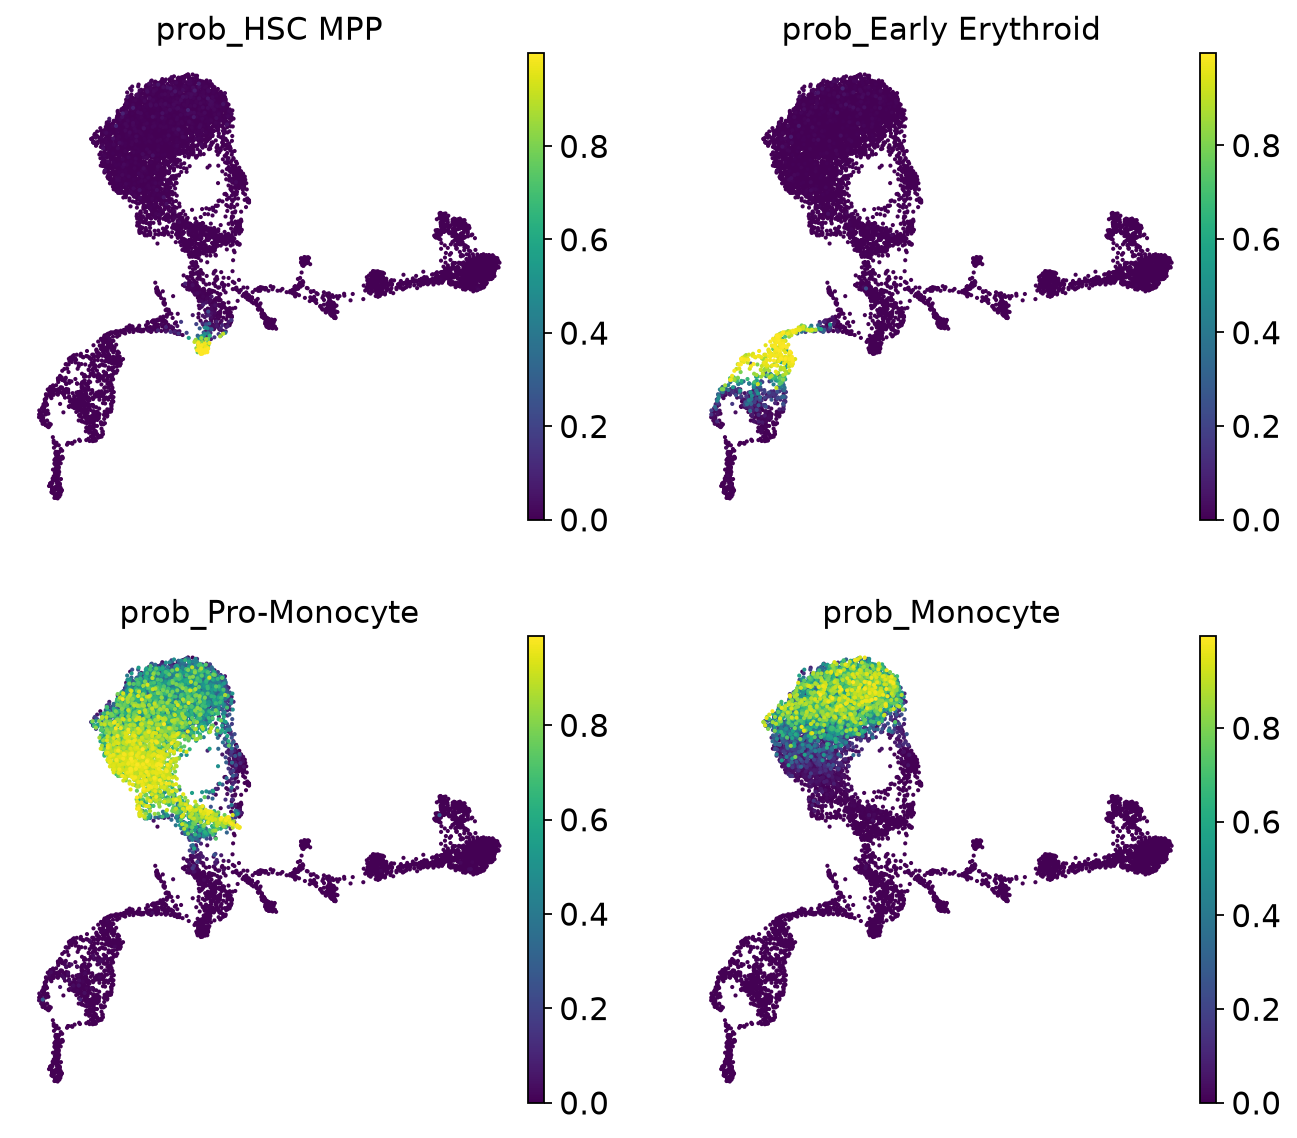

In [9]:
vm.viewmastR(query, ref, label, selected_features=vg, max_epochs=4, return_probs=True)
prob_cols = [f"prob_{k}" for k in ("HSC MPP", "Early Erythroid", "Pro-Monocyte", "Monocyte")]
sc.pl.umap(query, color=prob_cols, ncols=2, cmap="viridis")

## Versions

In [10]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
